In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

# ======== 1. Data Loading ========

calendar = pd.read_csv(
    r"E:\data_analysis\projects\AdventureWorks\data\AdventureWorks_Calendar.csv"
)

customers = pd.read_csv(
    r"E:\data_analysis\projects\AdventureWorks\data\AdventureWorks_Customers.csv",
    encoding="latin1"
)

category = pd.read_csv(
    r"E:\data_analysis\projects\AdventureWorks\data\AdventureWorks_Product_Categories.csv"
)

subcategory = pd.read_csv(
    r"E:\data_analysis\projects\AdventureWorks\data\AdventureWorks_Product_Subcategories.csv"
)

products = pd.read_csv(
    r"E:\data_analysis\projects\AdventureWorks\data\AdventureWorks_Products.csv"
)

returns = pd.read_csv(
    r"E:\data_analysis\projects\AdventureWorks\data\AdventureWorks_Returns.csv"
)

sales_2015 = pd.read_csv(
    r"E:\data_analysis\projects\AdventureWorks\data\AdventureWorks_Sales_2015.csv"
)

sales_2016 = pd.read_csv(
    r"E:\data_analysis\projects\AdventureWorks\data\AdventureWorks_Sales_2016.csv"
)

sales_2017 = pd.read_csv(
    r"E:\data_analysis\projects\AdventureWorks\data\AdventureWorks_Sales_2017.csv"
)

territories = pd.read_csv(
    r"E:\data_analysis\projects\AdventureWorks\data\AdventureWorks_Territories.csv"
)
#Concatenate sales tables 
# Concatenate sales tables

sales_list = [
    sales_2015,
    sales_2016,
    sales_2017
]

sales = pd.concat(
    sales_list,
    axis=0,
    ignore_index=True
)


# Data Understanding
# ======== 2. Data Understanding ========

tables = [
    ("Calendar", calendar),
    ("Customers", customers),
    ("Product Categories", category),
    ("Product Subcategories", subcategory),
    ("Products", products),
    ("Returns", returns),
    ("Sales", sales),
    ("Territories", territories)
]

for name, df in tables:

    print(f"\n{'=' * 50}")
    print(f"Table: {name}")
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")

    nulls = df.isnull().sum()
    print(f"Null:\n{nulls[nulls > 0]}")

    print(f"Duplicates: {df.duplicated().sum()}")
    print(f"Describe:\n{df.describe()}")
    
# ======== Validate Foreign Keys ========

print(
    "ProductKey match:",
    sales["ProductKey"].isin(products["ProductKey"]).mean()
)

print(
    "CustomerKey match:",
    sales["CustomerKey"].isin(customers["CustomerKey"]).mean()
)

print(
    "TerritoryKey match:",
    sales["TerritoryKey"].isin(territories["SalesTerritoryKey"]).mean()
)



Table: Calendar
Shape: (912, 1)
Columns: ['Date']
Null:
Series([], dtype: int64)
Duplicates: 0
Describe:
            Date
count        912
unique       912
top     1/1/2015
freq           1

Table: Customers
Shape: (18148, 13)
Columns: ['CustomerKey', 'Prefix', 'FirstName', 'LastName', 'BirthDate', 'MaritalStatus', 'Gender', 'EmailAddress', 'AnnualIncome', 'TotalChildren', 'EducationLevel', 'Occupation', 'HomeOwner']
Null:
Prefix    130
Gender    130
dtype: int64
Duplicates: 0
Describe:
        CustomerKey  TotalChildren
count  18148.000000   18148.000000
mean   20247.470465       1.843619
std     5336.245656       1.613203
min    11000.000000       0.000000
25%    15626.750000       0.000000
50%    20252.500000       2.000000
75%    24868.250000       3.000000
max    29483.000000       5.000000

Table: Product Categories
Shape: (4, 2)
Columns: ['ProductCategoryKey', 'CategoryName']
Null:
Series([], dtype: int64)
Duplicates: 0
Describe:
       ProductCategoryKey
count            4.000

In [2]:
# ======== Create SQLite Database ========

conn = sqlite3.connect(":memory:")

calendar.to_sql("calendar", conn, index=False)
customers.to_sql("customers", conn, index=False)
category.to_sql("category", conn, index=False)
subcategory.to_sql("subcategory", conn, index=False)
products.to_sql("products", conn, index=False)
returns.to_sql("returns", conn, index=False)
sales.to_sql("sales", conn, index=False)
territories.to_sql("territories", conn, index=False)


# SQL query function

def sql(query):
    return pd.read_sql_query(query, conn)
    
print(category.columns.tolist())

['ProductCategoryKey', 'CategoryName']


In [9]:
# ======== . Exploratory Data Analysis ========

# 1- Which regions generate the most revenue and gross profit, and how efficiently do they convert revenue into profit?


q1_result = sql("""
    SELECT 
       t.Region,
       SUM(s.OrderQuantity * p.ProductPrice) AS Revenue,
       SUM(s.OrderQuantity * p.ProductCost) AS Cost,
       SUM(s.OrderQuantity * (p.ProductPrice - p.ProductCost)) AS GrossProfit,
       SUM(s.OrderQuantity * (p.ProductPrice - p.ProductCost)) / SUM(s.OrderQuantity * p.ProductPrice) AS GrossMargin
    FROM sales s
    INNER JOIN territories t
       ON s.TerritoryKey = t.SalesTerritoryKey
    INNER JOIN products p
       ON s.ProductKey = p.ProductKey
    GROUP BY t.Region
    ORDER BY Revenue DESC
""")

#Q2 - Which products have high sales but low profit margins?
result = sql("""
   SELECT 
      p.ProductKey,
      p.ProductName,
      SUM(OrderQuantity) AS TotalQuantity,
      SUM(s.OrderQuantity * p.ProductPrice) AS Revenue,
      SUM(s.OrderQuantity * p.ProductPrice) - SUM(s.OrderQuantity * p.ProductCost) AS GrossProfit,
      SUM(s.OrderQuantity * (p.ProductPrice - p.ProductCost)) / SUM(s.OrderQuantity * p.ProductPrice) AS GrossMargin
      FROM sales s
      INNER JOIN Products p
         ON s.ProductKey = p.ProductKey
      GROUP BY 
         p.ProductKey,
         p.ProductName
""")

revenue_median = result["Revenue"].median()
margin_median = result["GrossMargin"].median()

result[["Revenue", "GrossMargin"]].describe()

result[
    (result["Revenue"] > revenue_median) &
    (result["GrossMargin"] < margin_median)
    ].sort_values("Revenue", ascending = False)

sql("""
SELECT
    p.ProductKey,
    p.ProductName,
    p.ProductPrice,
    p.ProductCost,
    p.ProductPrice - p.ProductCost AS ProfitPerUnit,
    (p.ProductPrice - p.ProductCost) / p.ProductPrice AS GrossMargin
FROM products p
WHERE p.ProductKey IN (
    580, 581, 369, 583, 582, 368, 370
)
ORDER BY GrossMargin ASC
""")

total_gross_profit = result["GrossProfit"].sum()



high_rev_low_margin = result[
    (result["Revenue"] > revenue_median) &
    (result["GrossMargin"] < margin_median)
]

high_rev_low_margin["GrossProfit"].sum()

high_rev_low_margin["GrossProfit"].sum() / total_gross_profit 

#Q3 - What share of revenue and profit comes from top 20% of products? 
result.columns
result[["Revenue", "GrossProfit"]].describe()
top20 = result.sort_values(
    "Revenue",
    ascending=False
).head(26)

top20_revenue = top20["Revenue"].sum()
total_revenue = result["Revenue"].sum()
revenue_share = (
    top20_revenue / total_revenue
) * 100

top20_profit = top20["GrossProfit"].sum()

total_profit = result["GrossProfit"].sum()

profit_share = (top20_profit / total_profit) * 100

"""
Top 20% products are responsible for roughly two-thirds of both revenue and gross profit,
indicating strong concentration of business value among a relatively small group of products.

Note: AdventureWorks sells both high-value bicycles and low-cost accessories. 
The revenue concentration partly reflects natural price differences across categories
rather than solely sales volume differences. The finding remains strategically valid:
losing top products would have disproportionate business impact regardless of the cause.
"""

# Category revenue breakdown to contextualize Pareto finding
category_revenue = sql("""
    SELECT 
        c.CategoryName,
        SUM(s.OrderQuantity * p.ProductPrice) AS Revenue,
        ROUND(
            SUM(s.OrderQuantity * p.ProductPrice) / 
            (SELECT SUM(s2.OrderQuantity * p2.ProductPrice) 
             FROM sales s2 
             INNER JOIN products p2 ON s2.ProductKey = p2.ProductKey) * 100,
        2) AS RevenueSharePct
    FROM sales s
    INNER JOIN products p ON s.ProductKey = p.ProductKey
    INNER JOIN subcategory sub ON p.ProductSubcategoryKey = sub.ProductSubcategoryKey
    INNER JOIN category c ON sub.ProductCategoryKey = c.ProductCategoryKey
    GROUP BY c.CategoryName
    ORDER BY Revenue DESC
""")

print("Revenue share by category:")
print(category_revenue)


#Q4 - What percentage of customers return, and is the company too dependent on new customer acquisition?
q4_customer_year = sql("""
   SELECT 
      substr(OrderDate, -4) AS Year,
      CustomerKey,
      COUNT(DISTINCT OrderNumber) AS UniqueOrders
    FROM sales s
    GROUP BY
       Year,
       CustomerKey
""")

# How many distinct years each customer appears in
customer_year_count = q4_customer_year.groupby("CustomerKey")["Year"].nunique()

# True returning = appeared in more than one year across full dataset
true_returning_total = (customer_year_count > 1).sum()
total_customers_ever = customer_year_count.shape[0]
true_returning_rate = (true_returning_total / total_customers_ever) * 100

print(f"Total unique customers (2015-2017): {total_customers_ever}")
print(f"Customers who returned across years: {true_returning_total}")
print(f"True cross-year retention rate: {true_returning_rate:.1f}%")

# Also keep year-by-year summary for the chart
q4_summary = q4_customer_year.groupby("Year").agg(
    TotalCustomers=("CustomerKey", "count"),
)

# Mark returning within year (kept for trend visualization)
q4_customer_year["WithinYearReturning"] = q4_customer_year["UniqueOrders"].apply(
    lambda x: "Returning" if x > 1 else "One-time"
)

within_year = q4_customer_year.groupby("Year").agg(
    ReturningCustomers=("WithinYearReturning", lambda x: (x == "Returning").sum())
)

q4_summary = q4_summary.join(within_year)
q4_summary["ReturningRate"] = (
    (q4_summary["ReturningCustomers"] / q4_summary["TotalCustomers"]) * 100
).round(2)

print(q4_summary)

#Q5 - What is the biggest driver of revenue growth: more customers, more orders per customer, or higher order value?
q5_summary = sql("""
   SELECT 
      substr(s.OrderDate, -4) AS Year, 
      COUNT(DISTINCT s.CustomerKey) AS TotalCustomers,
      COUNT(DISTINCT s.OrderNumber) AS TotalOrders,
      SUM(s.OrderQuantity * p.ProductPrice) AS Revenue
    FROM sales s 
    INNER JOIN products p
       ON s.ProductKey = p.ProductKey
    GROUP BY Year
    ORDER BY Year 
""")
q5_summary
#Order Per Customer 
q5_summary["OrderPerCustomer"] = (
    q5_summary["TotalOrders"] / 
    q5_summary["TotalCustomers"]
)
q5_summary["OrderPerCustomer"]
q5_summary
#Average Order Value
q5_summary["AOV"] = (
    q5_summary["Revenue"] / 
    q5_summary["TotalOrders"]
)
q5_summary["AOV"]
q5_summary

q5_growth = q5_summary.copy()

q5_growth["CustomerGrowth"] = (
    q5_growth["TotalCustomers"].pct_change() * 100
)

q5_growth["OrdersPerCustomerGrowth"] = (
    q5_growth["OrderPerCustomer"].pct_change() * 100
)

q5_growth["AOVGrowth"] = (
    q5_growth["AOV"].pct_change() * 100
)

q5_growth["RevenueGrowth"] = (
    q5_growth["Revenue"].pct_change() * 100
)

q5_growth[
    [
        "Year",
        "RevenueGrowth",
        "CustomerGrowth",
        "OrdersPerCustomerGrowth",
        "AOVGrowth"
    ]
]
q5_growth


#Q6 - Which customer groups generate highest lifetime value and where should retention resources focus?
q6_customer = sql("""
   SELECT 
      s.CustomerKey,
      COUNT(DISTINCT s.OrderNumber) AS TotalOrders,
      SUM(s.OrderQuantity) AS TotalQuantity,
      SUM(s.OrderQuantity * p.ProductPrice) AS Revenue,
      SUM(s.OrderQuantity * (p.ProductPrice - p.ProductCost)) AS GrossProfit,
      MIN (s.OrderDate) AS FirstOrderDate,
      MAX (s.OrderDate) AS LastOrderDate
    FROM sales s
    INNER JOIN products p
       ON s.ProductKey = p.ProductKey
    GROUP BY s.CustomerKey
    ORDER BY GrossProfit
""")

q6_customer.shape
q6_customer["CustomerKey"].nunique()
len(q6_customer)
q6_customer.head(20)
q6_customer["TotalOrders"].describe()
q6_customer["Revenue"].describe()
q6_customer["GrossProfit"].describe()
q6_customer[
    ["TotalOrders", "Revenue", "GrossProfit"]
    ].corr()

q6_customer["GrossMargin"] = q6_customer["GrossProfit"] / q6_customer["Revenue"]
q6_customer["GrossMargin"].describe()

q6_customer["LastOrderDate"] = pd.to_datetime(
    q6_customer["LastOrderDate"]
)
q6_customer["FirstOrderDate"] = pd.to_datetime(
    q6_customer["FirstOrderDate"]
)
q6_customer["LifetimeDays"] = (
    q6_customer["LastOrderDate"] -
    q6_customer["FirstOrderDate"]
).dt.days    

q6_customer["LifetimeDays"]

#Q7 - Which markets generate highest economic value despite lower customer count?
q7_table = sql("""
   SELECT 
     SUM(OrderQuantity * (ProductPrice - ProductCost)) AS GrossProfit,
     COUNT(DISTINCT s.CustomerKey) AS TotalCustomers,
     t.Country
    FROM sales s
    INNER JOIN Products p 
       ON s.ProductKey = p.ProductKey
    INNER JOIN territories t
       ON s.TerritoryKey = t.SalesTerritoryKey
    GROUP BY t.Country
""")

q7_table["GrossProfitperCustomer"] = q7_table["GrossProfit"] / q7_table["TotalCustomers"]
q7_table.sort_values("GrossProfitperCustomer", ascending = False)


#Q8 - What seasonal and time-based patterns exist in sales, and when does the business experience its strongest and weakest sales periods?

q8_table = sql("""
   SELECT
      substr(s.OrderDate, -4) AS Year,
      CAST(substr(s.OrderDate, 1, instr(s.OrderDate, '/') - 1) AS INTEGER) AS Month,
      SUM(s.OrderQuantity * p.ProductPrice) AS Revenue,
      SUM(OrderQuantity * (ProductPrice - ProductCost)) AS GrossProfit,
      COUNT(DISTINCT OrderNumber) AS OrderCount
    FROM sales s 
    INNER JOIN Products p
       ON s.ProductKey = p.ProductKey
    GROUP BY 
       Year,
       Month
    ORDER BY 
       Year,
       Month
""")
q8_table 

#Q9 - Which products generate the greatest economic loss from returns, and where would reducing returns create the most financial value?
q9_table = sql("""
   SELECT
      p.ProductName,
      p.ProductKey,
      p.ProductCost,
      COALESCE(s.SoldQuantity, 0) AS SoldQuantity,
      COALESCE(r.ReturnedQuantity, 0) AS ReturnedQuantity
    FROM Products p 
    LEFT JOIN (
       SELECT
          ProductKey,
          SUM(OrderQuantity) AS SoldQuantity
        FROM sales
        GROUP BY ProductKey
    )s
       ON p.Productkey = s.ProductKey
    LEFT JOIN (
       SELECT 
          ProductKey,
          SUM(ReturnQuantity) AS ReturnedQuantity
        FROM Returns 
        GROUP BY ProductKey
    ) r
       ON p.ProductKey = r.ProductKey
    GROUP BY p.ProductKey
""")

q9_table      

#ReturnProductCost KPI
q9_table["ReturnProductCost"] = q9_table["ReturnedQuantity"] *q9_table["ProductCost"]
q9_table

#ReturnRate
q9_table["ReturnRate"] = (q9_table["ReturnedQuantity"] / q9_table["SoldQuantity"]) * 100
q9_table




Revenue share by category:
  CategoryName       Revenue  RevenueSharePct
0        Bikes  2.364250e+07            94.89
1  Accessories  9.066731e+05             3.64
2     Clothing  3.654186e+05             1.47
Total unique customers (2015-2017): 17416
Customers who returned across years: 4551
True cross-year retention rate: 26.1%
      TotalCustomers  ReturningCustomers  ReturningRate
Year                                                   
2015            2630                   0           0.00
2016            9133                1209          13.24
2017           10502                 947           9.02


,ProductName,ProductKey,ProductCost,SoldQuantity,ReturnedQuantity,ReturnProductCost,ReturnRate
0,"Sport-100 Helmet, Red",214,13.0863,2099,70,916.0410,3.334921
1,"Sport-100 Helmet, Black",215,12.0278,1940,52,625.4456,2.680412
2,"Mountain Bike Socks, M",218,3.3963,0,0,0.0000,NaN
3,"Mountain Bike Socks, L",219,3.3963,0,0,0.0000,NaN
4,"Sport-100 Helmet, Blue",220,12.0278,1995,66,793.8348,3.308271
...,...,...,...,...,...,...,...
288,ML Bottom Bracket,602,44.9506,0,0,0.0000,NaN
289,HL Bottom Bracket,603,53.9416,0,0,0.0000,NaN
290,"Road-750 Black, 44",604,343.6496,356,7,2405.5472,1.966292
291,"Road-750 Black, 48",605,343.6496,355,15,5154.7440,4.225352


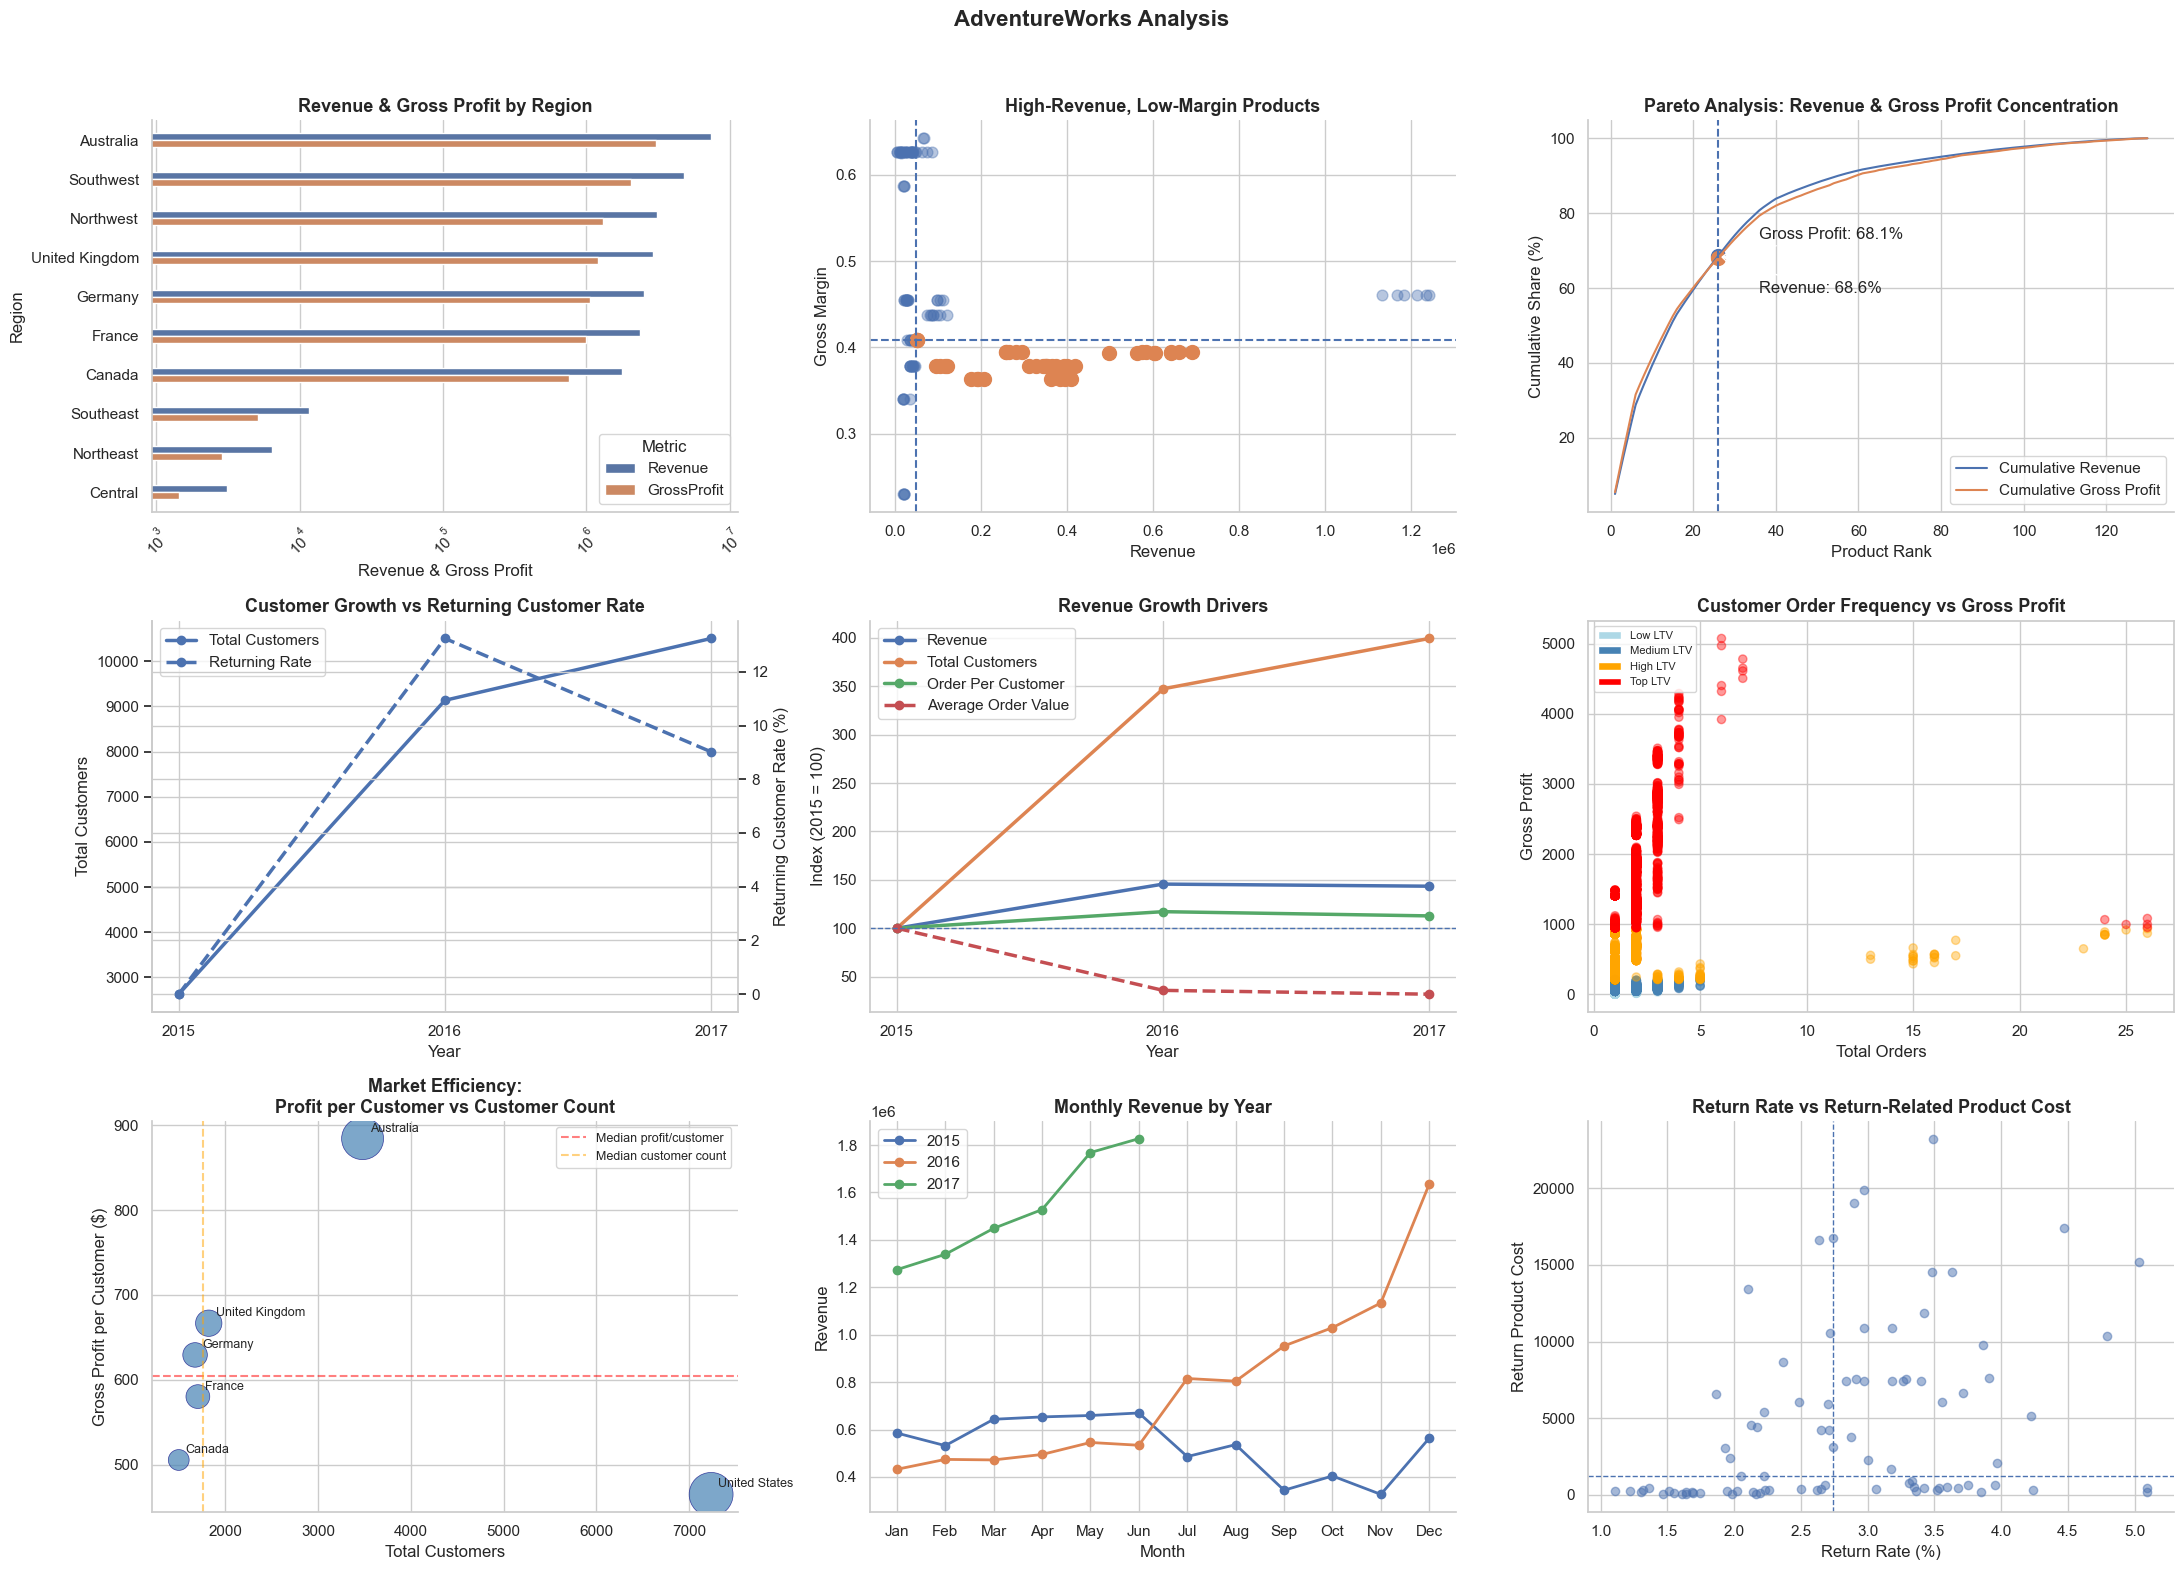

In [10]:
#======== 5. Data Visualisation ========

#Create 3 * 3 Dashboard
fig, axes = plt.subplots(3, 3, figsize = (22, 16))
sns.set_theme(style="whitegrid")

# 1- Which regions generate the most revenue and gross profit, and how efficiently do they convert revenue into profit?
q1_result["GrossMargin"] = (
    q1_result["GrossProfit"] /
    q1_result["Revenue"]
) * 100

q1_chart = q1_result.melt(
    id_vars="Region",
    value_vars=["Revenue", "GrossProfit"],
    var_name="Metric",
    value_name="Value"
)

sns.barplot(
    data = q1_chart,
    x="Value",
    y="Region",
    hue = "Metric",
    width = 0.35,
    ax = axes[0,0]
)
axes[0,0].set_xscale("log")
axes[0,0].set_title("Revenue & Gross Profit by Region", fontsize = 13, fontweight = "bold")
axes[0,0].set_xlabel("Revenue & Gross Profit")
axes[0,0].set_ylabel("Region")
axes[0,0].tick_params(axis='x', rotation=45)
axes[0, 0].spines['top'].set_visible(False)
axes[0, 0].spines['right'].set_visible(False)

#Q2 - Which products have high sales but low profit margins?
axes[0, 1].scatter(result["Revenue"], result["GrossMargin"], alpha = 0.4, s = 60)
axes[0, 1].axvline(revenue_median, linestyle = "--")
axes[0, 1].axhline(margin_median, linestyle="--")
axes[0, 1].scatter(
    high_rev_low_margin["Revenue"],
    high_rev_low_margin["GrossMargin"],
    s=100
)

axes[0, 1].set_title("High-Revenue, Low-Margin Products", fontsize = 13, fontweight = "bold")
axes[0, 1].set_xlabel("Revenue")
axes[0, 1].set_ylabel("Gross Margin")
axes[0, 1].spines["top"].set_visible(False)
axes[0, 1].spines["right"].set_visible(False)


# Q3 - What share of revenue and gross profit comes from the top 20% of products?

pareto = result.sort_values("Revenue", ascending=False).copy()

# Product rank
pareto["ProductRank"] = range(1, len(pareto) + 1)

# Cumulative Revenue
pareto["CumulativeRevenue"] = pareto["Revenue"].cumsum()
pareto["CumulativeRevenuePct"] = (
    pareto["CumulativeRevenue"] / pareto["Revenue"].sum()
) * 100

# Cumulative Gross Profit
pareto["CumulativeGrossProfit"] = pareto["GrossProfit"].cumsum()
pareto["CumulativeGrossProfitPct"] = (
    pareto["CumulativeGrossProfit"] / pareto["GrossProfit"].sum()
) * 100

# Top 20%
n_top20 = math.ceil(len(pareto) * 0.20)

revenue_share = pareto.loc[
    pareto["ProductRank"] == n_top20,
    "CumulativeRevenuePct"
].iloc[0]

profit_share = pareto.loc[
    pareto["ProductRank"] == n_top20,
    "CumulativeGrossProfitPct"
].iloc[0]

ax = axes[0, 2]

# Revenue and Gross Profit on the same chart
ax.plot(
    pareto["ProductRank"],
    pareto["CumulativeRevenuePct"],
    label="Cumulative Revenue"
)

ax.plot(
    pareto["ProductRank"],
    pareto["CumulativeGrossProfitPct"],
    label="Cumulative Gross Profit"
)

# Top 20% reference
ax.axvline(
    x=n_top20,
    linestyle="--"
)

# Mark the two shares
ax.scatter(n_top20, revenue_share, s=100)
ax.scatter(n_top20, profit_share, s=100)

ax.annotate(
    f"Revenue: {revenue_share:.1f}%",
    xy=(n_top20, revenue_share),
    xytext=(n_top20 + 10, revenue_share - 10),
    arrowprops=dict(arrowstyle="->")
)

ax.annotate(
    f"Gross Profit: {profit_share:.1f}%",
    xy=(n_top20, profit_share),
    xytext=(n_top20 + 10, profit_share + 5),
    arrowprops=dict(arrowstyle="->")
)

ax.set_title("Pareto Analysis: Revenue & Gross Profit Concentration", fontsize = 13, fontweight = "bold")
ax.set_xlabel("Product Rank")
ax.set_ylabel("Cumulative Share (%)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend()
# Q4 — Total Customers vs Returning Customer Rate

ax = axes[1, 0]
ax.plot(
    q4_summary.index,
    q4_summary["TotalCustomers"],
    marker="o",
    linewidth=2.5,
    label="Total Customers"
)
ax.set_xlabel("Year")
ax.set_ylabel("Total Customers")
ax.set_title("Customer Growth vs Returning Customer Rate", fontsize = 13, fontweight = "bold")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)   

ax2 = ax.twinx()
ax2.plot(
    q4_summary.index,
    q4_summary["ReturningRate"],
    marker = "o",
    linewidth = 2.5,
    linestyle = "--",
    label = "Returning Rate"
)

ax2.set_ylabel("Returning Customer Rate (%)")


ax2.spines["top"].set_visible(False)

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left"
)

#Q5 - What is the biggest driver of revenue growth: more customers, more orders per customer, or higher order value?
q5_index = q5_summary.copy()

q5_index["RevenueIndex"] = (q5_index["Revenue"] / q5_index["Revenue"].iloc[0]) * 100
q5_index["Customersindex"] = (q5_index["TotalCustomers"] / q5_index["TotalCustomers"].iloc[0]) * 100
q5_index["OrderPerCustomerIndex"] = (q5_index["OrderPerCustomer"] / q5_index["OrderPerCustomer"].iloc[0]) * 100
q5_index["AOVIndex"] = (q5_index["AOV"] / q5_index["AOV"].iloc[0]) * 100
                                     
ax = axes[1, 1]
ax.plot(
    q5_index["Year"],
    q5_index["RevenueIndex"],
    marker = "o",
    linewidth = 2.5,
    label = "Revenue"
)

ax.plot(
    q5_index["Year"],
    q5_index["Customersindex"],
    marker = "o",
    linewidth = 2.5,
    label = "Total Customers"
)

ax.plot(
    q5_index["Year"],
    q5_index["OrderPerCustomerIndex"],
    marker = "o",
    linewidth = 2.5,
    label = "Order Per Customer"
)

ax.plot(
    q5_index["Year"],
    q5_index["AOVIndex"],
    marker = "o",
    linewidth = 2.5,
    linestyle = "--",
    label = "Average Order Value"
)

ax.axhline(
    100,
    linestyle = "--",
    linewidth = 1
)

ax.set_title("Revenue Growth Drivers", fontsize = 13, fontweight = "bold")
ax.set_xlabel("Year")
ax.set_ylabel("Index (2015 = 100)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend()

#Q6 - Which customer groups generate highest lifetime value and where should retention resources focus?

q6_customer['LTVSegment'] = pd.qcut(
    q6_customer['GrossProfit'],
    q=4,
    labels=['Low', 'Medium', 'High', 'Top'],
    duplicates='drop'
)

colors_map = {'Low': 'lightblue', 'Medium': 'steelblue', 'High': 'orange', 'Top': 'red'}
colors = q6_customer['LTVSegment'].map(colors_map)
axes[1, 2].scatter(
    q6_customer["TotalOrders"],
    q6_customer["GrossProfit"],
    c = colors,
    alpha = 0.4,
    s = 35
)


axes[1, 2].legend(handles=legend_elements, loc='upper left', fontsize=8)
axes[1, 2].set_title("Customer Order Frequency vs Gross Profit", fontsize = 13, fontweight = "bold")
axes[1, 2].set_xlabel("Total Orders")
axes[1, 2].set_ylabel("Gross Profit")


#Q7 - Which markets generate highest economic value despite lower customer count?

ax = axes[2, 0]
scatter = ax.scatter(
    q7_table['TotalCustomers'],
    q7_table['GrossProfitperCustomer'],
    s=q7_table['GrossProfit'] / q7_table['GrossProfit'].max() * 1000,
    alpha=0.7,
    color='steelblue',
    edgecolors='navy',
    linewidth=0.5
)

# Annotate each country
for _, row in q7_table.iterrows():
    ax.annotate(
        row['Country'],
        (row['TotalCustomers'], row['GrossProfitperCustomer']),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=9
    )

# Add reference lines at medians
ax.axhline(
    y=q7_table['GrossProfitperCustomer'].median(),
    color='red', linestyle='--', alpha=0.5,
    label='Median profit/customer'
)
ax.axvline(
    x=q7_table['TotalCustomers'].median(),
    color='orange', linestyle='--', alpha=0.5,
    label='Median customer count'
)

ax.set_xlabel('Total Customers', fontsize=12)
ax.set_ylabel('Gross Profit per Customer ($)', fontsize=12)
ax.set_title('Market Efficiency:\nProfit per Customer vs Customer Count', fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

#Q8 - Q8 - What seasonal and time-based patterns exist in sales?
q8_table["MonthName"] = q8_table["Month"].apply(
    lambda x: pd.Timestamp(2024, int(x), 1).strftime("%b")
)

q8_table["Year"] = q8_table["Year"].astype(int)

q8_table = q8_table.sort_values(
    ["Year", "Month"]
)

data_2015 = q8_table[q8_table["Year"] == 2015]
data_2016 = q8_table[q8_table["Year"] == 2016]
data_2017 = q8_table[q8_table["Year"] == 2017]

ax = axes[2, 1]
#2015
ax.plot(
    data_2015["MonthName"],
    data_2015["Revenue"],
    marker = "o",
    linewidth = 2,
    label = "2015"
)

#2016
ax.plot(
    data_2016["MonthName"],
    data_2016["Revenue"],
    marker = "o",
    linewidth = 2,
    label = "2016"
)

#2017
ax.plot(
    data_2017["MonthName"],
    data_2017["Revenue"],
    marker = "o",
    linewidth = 2,
    label = "2017"
)
        
ax.set_xlabel("Month")
ax.set_ylabel("Revenue")
ax.set_title("Monthly Revenue by Year", fontsize = 13, fontweight = "bold")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)   
ax.legend()

#Q9 - Which products generate the greatest economic loss from returns, and where would reducing returns create the most financial value?

# Keep products with meaningful sales volume
q9_table = q9_table[
    q9_table["SoldQuantity"] >= 100
].copy()

"""
Methodology note:
- Filtered to products with 100+ units sold to ensure statistical relevance
- High return rates may reflect legitimate factors (sizing issues, seasonal products,
  product category norms) that this dataset cannot distinguish from quality problems
- Return cost calculated as: ReturnedQuantity × ProductCost (replacement cost basis)
- Recommendation: products in upper-right quadrant (high rate + high cost) should be 
  investigated further before assuming quality failure as root cause
"""

q9_table["ReturnProductCost"] = (
    q9_table["ReturnedQuantity"] * q9_table["ProductCost"]
)

# Calculate return rate
q9_table["ReturnRate"] = (
    q9_table["ReturnedQuantity"] /
    q9_table["SoldQuantity"]
) * 100

#Calculate median reference points
rate_median = q9_table["ReturnRate"].median()
cost_median = q9_table["ReturnProductCost"].median()

ax = axes[2, 2]
ax.scatter(
    q9_table["ReturnRate"],
    q9_table["ReturnProductCost"],
    alpha = 0.5
)

# Add median reference lines
ax.axvline(
    rate_median,
    linestyle = "--",
    linewidth = 1
)

ax.axhline(
    cost_median,
    linestyle = "--",
    linewidth = 1
)

ax.set_xlabel("Return Rate (%)")
ax.set_ylabel("Return Product Cost")
ax.set_title(
    "Return Rate vs Return-Related Product Cost",
    fontsize=13,
    fontweight="bold"
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)  


plt.suptitle('AdventureWorks Analysis', fontsize = 16, fontweight= 'bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(r'E:\data_analysis\projects\AdventureWorks\visuals\dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()